In [1]:
import numpy as np
from pathlib import Path
import tifffile as tiff
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import scipy.stats as stats

Function to define significance of p-value

In [2]:
def convert_pvalue_to_asterisks(pvalue):
    if pvalue <= 0.0001:
        return "****"
    elif pvalue <= 0.001:
        return "***"
    elif pvalue <= 0.01:
        return "**"
    elif pvalue <= 0.05:
        return "*"
    return "ns"

In [35]:
folder = Path('output')
pixel_size = 0.11 # in microns

all_spots = pd.DataFrame()
for file in folder.glob('*fish_spots_distances.csv'):
    # read all files and concatenate them
    df = pd.read_csv(file)
    all_spots = pd.concat([all_spots, df])

all_mito = pd.DataFrame()
for file in folder.glob('*mito_distances.csv'):
    # read all files and concatenate them
    df = pd.read_csv(file)
    all_mito = pd.concat([all_mito, df])

all_random_spots = pd.DataFrame()
for file in folder.glob('*random_spots_distances.csv'):
    # read all files and concatenate them
    df = pd.read_csv(file)
    all_random_spots = pd.concat([all_random_spots, df])

#remove location='CoM' and 'nucleus' rows from all_spots dataframe
plot_spots = all_spots[all_spots.location.isin(['mito', 'out'])]
plot_rand_spots = all_random_spots[all_random_spots.location.isin(['mito', 'out'])]

In [36]:
#save the plot_spots dataframe as a csv
plot_spots.to_csv('all_FISH_foci.csv', index=False)
plot_rand_spots.to_csv('all_random_spots.csv', index=False)
all_mito.to_csv('all_mito_segmented_pixels.csv', index=False)

In [37]:
plot_spots = pd.read_csv('all_FISH_foci.csv', index_col=0)
plot_rand_spots = pd.read_csv('all_random_spots.csv', index_col=0)
all_mito = pd.read_csv('all_mito_segmented_pixels.csv', index_col=0)

Number of random spots

In [39]:
len(plot_rand_spots)

12989

Number of real FISH foci in the data

In [40]:
len(plot_spots)

11788

In [41]:
plot_spots.groupby('location')['distance'].median()*0.103

location
mito    13.776447
out     20.600082
Name: distance, dtype: float64

In [42]:
plot_rand_spots.groupby('location')['distance'].median()*0.103

location
mito    15.027105
out     26.589725
Name: distance, dtype: float64

# Big overall distribution of all foci

c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na opti

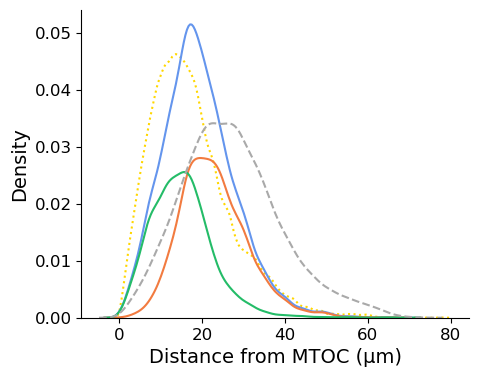

In [28]:
custom_palette = ['#24bc68', '#F27B40']

fig, ax = plt.subplots(figsize=(5,4))

#sns.kdeplot(x=plot_spots['distance'], hue=plot_spots['location'])
sns.kdeplot(x=all_mito['distance']*pixel_size, color='gold', linestyle=':')
sns.kdeplot(x=plot_spots['distance']*pixel_size, color='cornflowerblue')
sns.kdeplot(x=plot_spots['distance']*pixel_size, hue=plot_spots['location'], palette=custom_palette, legend=False)

#sns.kdeplot(x=plot_rand_spots['distance'], hue=plot_rand_spots['location'], linestyle='--')
sns.kdeplot(x=plot_rand_spots['distance']*pixel_size, color='darkgrey', linestyle='--')

plt.ylabel('Density', fontsize=14)
plt.xlabel('Distance from MTOC (µm)', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()
#plt.savefig('plots/FISH_kde.png', dpi=300, bbox_inches='tight')

# Grouping by cell for mito foci and cytoplasm foci
Taking the mean distance of all mito/cytoplasm foci for each cell

In [43]:
grouped_spots = plot_spots.groupby(['file', 'location']).distance.mean().reset_index()
grouped_spots.to_csv('FISH_foci_grouped_by_cell.csv', index=False)

In [44]:
grouped_spots = pd.read_csv('FISH_foci_grouped_by_cell.csv')

c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is depr

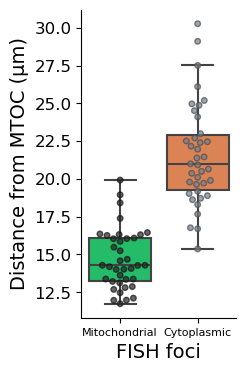

In [45]:
custom_palette = ['#0BD566', '#F27B40']

fig, ax = plt.subplots(figsize=(2,4))
sns.boxplot(x=grouped_spots['location'], y=grouped_spots['distance']*pixel_size, palette=custom_palette, showfliers=False)
sns.swarmplot(x=grouped_spots['location'], y=grouped_spots['distance']*pixel_size, hue=grouped_spots['location'], color="slategray", linewidth=1, alpha=0.7, size=4, legend=False)
plt.xticks([0, 1], ['Mitochondrial', 'Cytoplasmic'], fontsize=8)  # Set the tick labels manually
plt.xlabel('FISH foci', fontsize=14)
plt.yticks(fontsize=12)
plt.ylabel('Distance from MTOC (µm)', fontsize=14)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()
#plt.savefig('plots/FISH_foci_cell_avg.png', dpi=300, bbox_inches='tight')

In [33]:
stat, pvalue = stats.ttest_ind(grouped_spots[grouped_spots.location == 'mito'].distance, grouped_spots[grouped_spots.location == 'out'].distance)
stars = convert_pvalue_to_asterisks(pvalue)
print('pvalue = ', pvalue, ' ', stars)

pvalue =  5.584291816991252e-17   ****


### Old plot looking at the difference between mito and cyto foci (without averaging by cell)

c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


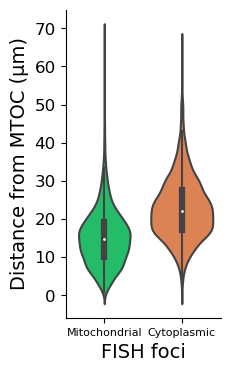

In [46]:
box_spots = plot_spots[plot_spots.location != 'nuc']

fig, ax = plt.subplots(figsize=(2,4))

#sns.stripplot(y=box_spots['distance']*0.11, x=box_spots['location'], color=".25", alpha=0.1, size=2, jitter=0.2)
#sns.boxplot(y=box_spots['distance']*0.11, x=box_spots['location'], fliersize=0, palette=custom_palette)
sns.violinplot(y=box_spots['distance']*0.11, x=box_spots['location'], palette=custom_palette, scale='count')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.xticks([0, 1], ['Mitochondrial', 'Cytoplasmic'], fontsize=8)  # Set the tick labels manually
plt.xlabel('FISH foci', fontsize=14)
plt.yticks(fontsize=12)
plt.ylabel('Distance from MTOC (µm)', fontsize=14)

plt.show()
#plt.savefig('plots/FISH_foci.png', dpi=300, bbox_inches='tight')

In [47]:
stat, pvalue = stats.ttest_ind(all_spots[all_spots.location == 'mito'].distance, all_spots[all_spots.location == 'out'].distance)
stars = convert_pvalue_to_asterisks(pvalue)
print('pvalue = ', pvalue, ' ', stars)

pvalue =  0.0   ****


# Same but comparing to the random foci as well

c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is depr

<Axes: xlabel='location', ylabel='distance'>

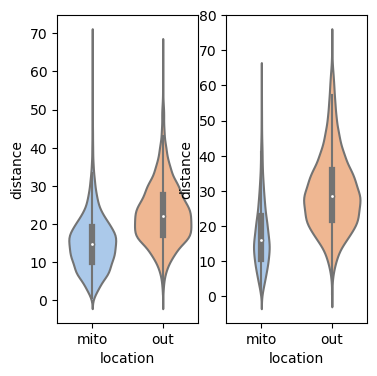

In [48]:
rand_box_spots = plot_rand_spots[plot_rand_spots.location != 'nuc']

fig, ax = plt.subplots(1,2,figsize=(4,4))
sns.violinplot(y=box_spots['distance']*0.11, x=box_spots['location'], palette='pastel', ax=ax[0], scale='count')
sns.violinplot(y=rand_box_spots['distance']*0.11, x=rand_box_spots['location'], palette='pastel', ax=ax[1], scale='count')

# Visualization example

In [49]:
image_name = '230915_NDUFA10_probe016_cell2'
image = tiff.imread('for_viz/' + image_name + '_MAX.tif')

In [50]:
spots_image = all_spots[all_spots.file == image_name]

c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is depr

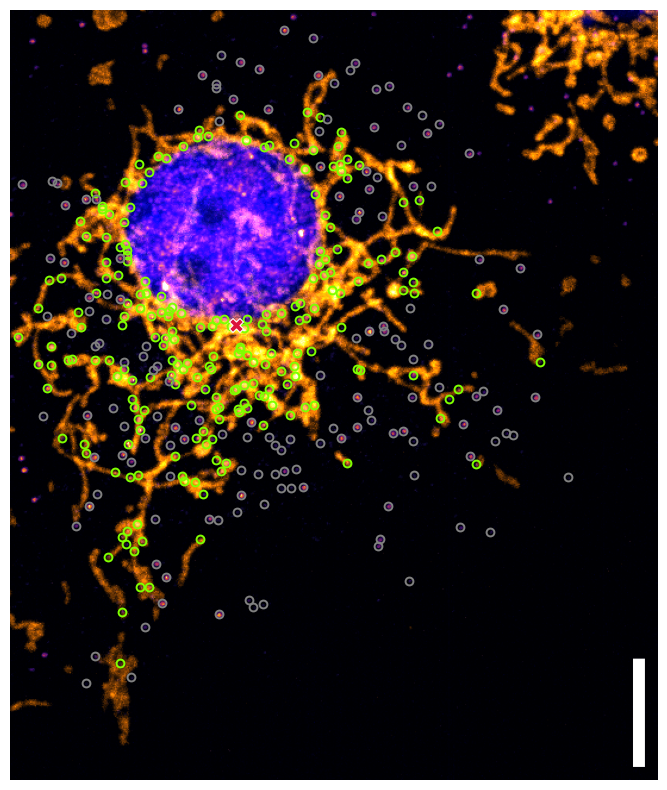

In [51]:
plt.figure(figsize=(10,10))
plt.imshow(image)
sns.scatterplot(data=spots_image[spots_image.location == 'mito'], y='x', x='y', s=50, linewidth=0, c='chartreuse', marker="$\circ$")#, label='mitochondrial')
sns.scatterplot(data=spots_image[spots_image.location == 'out'], y='x', x='y', s=50, linewidth=0, c='gray', marker="$\circ$")#, label='cytoplasmic')
sns.scatterplot(data=spots_image[spots_image.location == 'CoM'], y='x', x='y', s=100, c='crimson', marker='X')#, label='center of mass')
plt.axis('off')
#plt.legend(loc='lower left', framealpha=0.1, labelcolor='lightgray', fontsize=10)

plt.show()
#plt.savefig('plots/' + image_name + '_spots.jpg', dpi=300, pad_inches=0, bbox_inches='tight')

### And the same for random points distributed over the cell

In [54]:
spots_image = all_random_spots[all_random_spots.file == '230915_NDUFA10_probe016_cell2']

c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is depr

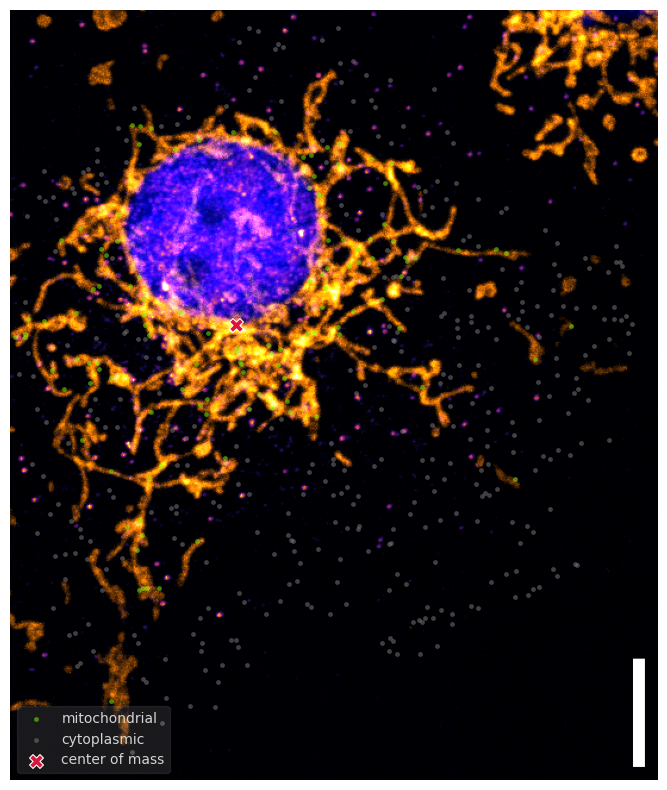

In [55]:
plt.figure(figsize=(10,10))
plt.imshow(image)
sns.scatterplot(data=spots_image[spots_image.location == 'mito'], y='x', x='y', s=12, c='chartreuse', linewidth=0, alpha=0.5, label='mitochondrial')
sns.scatterplot(data=spots_image[spots_image.location == 'out'], y='x', x='y', s=12, c='gray', linewidth=0, alpha=0.5, label='cytoplasmic')
sns.scatterplot(data=spots_image[spots_image.location == 'CoM'], y='x', x='y', s=100, c='crimson', marker='X', label='center of mass')
plt.axis('off')
plt.legend(loc='lower left', framealpha=0.1, labelcolor='lightgray', fontsize=10)

plt.show()
#plt.savefig('plots/' + image_name + '_spots.jpg', dpi=300, bbox_inches='tight')

# Single slice analysis

In [56]:
folder = Path('output_single_slice')

all_spots = pd.DataFrame()
for file in folder.glob('*fish_spots_distances.csv'):
    # read all files and concatenate them
    df = pd.read_csv(file)
    all_spots = pd.concat([all_spots, df])

all_mito = pd.DataFrame()
for file in folder.glob('*mito_distances.csv'):
    # read all files and concatenate them
    df = pd.read_csv(file)
    all_mito = pd.concat([all_mito, df])

all_random_spots = pd.DataFrame()
for file in folder.glob('*random_spots_distances.csv'):
    # read all files and concatenate them
    df = pd.read_csv(file)
    all_random_spots = pd.concat([all_random_spots, df])

#remove location='CoM' and 'nucleus' rows from all_spots dataframe
plot_spots = all_spots[all_spots.location != 'CoM']
plot_rand_spots = all_random_spots[all_random_spots.location != 'CoM']

In [57]:
box_spots = plot_spots[plot_spots.location != 'nuc']
rand_box_spots = plot_rand_spots[plot_rand_spots.location != 'nuc']

In [60]:
box_spots['type'] = 'real'
rand_box_spots['type'] = 'random'

plotting_df = pd.concat([box_spots, rand_box_spots])
plotting_df.to_csv('single_slice_plotting_data.csv', index=False)

C:\Users\winter\AppData\Local\Temp\ipykernel_24936\890440053.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  box_spots['type'] = 'real'
C:\Users\winter\AppData\Local\Temp\ipykernel_24936\890440053.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  rand_box_spots['type'] = 'random'


In [61]:
plotting_df = pd.read_csv('single_slice_plotting_data.csv')

In [62]:
stat, pvalue = stats.ttest_ind(box_spots['distance'], rand_box_spots['distance'])
stars = convert_pvalue_to_asterisks(pvalue)
print('pvalue = ', pvalue, ' ', stars)

pvalue =  4.9714565048791e-310   ****


c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is depr

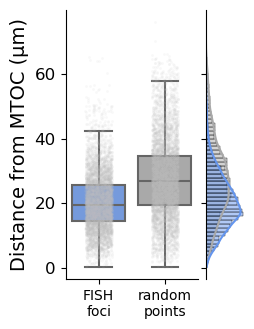

In [63]:
c_palette = ['cornflowerblue', 'darkgrey']
grid = sns.JointGrid(ratio=3)
grid.fig.set_size_inches(2,4)

sns.boxplot(plotting_df, y=plotting_df['distance']*pixel_size, x='type', palette=c_palette, showfliers=False, ax=grid.ax_joint)
sns.stripplot(plotting_df, y=plotting_df['distance']*pixel_size, x='type', color='silver', size=2, alpha=0.1, jitter=0.2, ax=grid.ax_joint)
sns.histplot(plotting_df, y=plotting_df['distance']*pixel_size, hue='type', palette=c_palette, kde=True, legend=False, ax=grid.ax_marg_y)

grid.ax_joint.set_ylabel('Distance from MTOC (µm)', fontsize=14)
grid.ax_joint.set_xlabel('')
grid.ax_joint.set_xticks([0, 1], ['FISH\nfoci', 'random\npoints'], fontsize=10)  # Set the tick labels manually
grid.ax_joint.tick_params(axis='y', labelsize=12)

grid.ax_marg_x.remove()

plt.show()
#plt.savefig('plots/FISH_foci_single_slice.png', dpi=300, bbox_inches='tight')